In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"

df = pd.read_csv(url)

print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [3]:
df.isnull().sum().sort_values(ascending=False)

company                           112593
agent                              16340
country                              488
children                               4
arrival_date_month                     0
arrival_date_week_number               0
hotel                                  0
is_canceled                            0
stays_in_weekend_nights                0
arrival_date_day_of_month              0
adults                                 0
stays_in_week_nights                   0
babies                                 0
meal                                   0
lead_time                              0
arrival_date_year                      0
distribution_channel                   0
market_segment                         0
previous_bookings_not_canceled         0
is_repeated_guest                      0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
previous_cancellations                 0
deposit_type    

In [4]:
df_model = df.drop(columns=[
    'company',
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type',
    'booking_changes',
    'days_in_waiting_list'
])

print(df_model.shape)

(119390, 26)


In [5]:
df_model['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [6]:
df_model['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

In [7]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df_model,
    test_size=0.2,
    random_state=42,
    stratify=df_model['is_canceled']
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=42,
    stratify=df_full_train['is_canceled']
)

print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)

Train: (71634, 26)
Validation: (23878, 26)
Test: (23878, 26)


In [8]:
y_train = df_train['is_canceled'].values
y_val = df_val['is_canceled'].values
y_test = df_test['is_canceled'].values

X_train = df_train.drop(columns=['is_canceled']).copy()
X_val = df_val.drop(columns=['is_canceled']).copy()
X_test = df_test.drop(columns=['is_canceled']).copy()

In [9]:
for data in [X_train, X_val, X_test]:
    data['children'] = data['children'].fillna(0)

    data['country'] = data['country'].fillna('unknown')

    data['agent'] = (
        data['agent']
        .fillna(-1)
        .astype(int)
        .astype(str)
    )

In [10]:
print("Train missing values:", X_train.isnull().sum().sum())
print("Validation missing values:", X_val.isnull().sum().sum())
print("Test missing values:", X_test.isnull().sum().sum())

print("X_train shape:", X_train.shape)

Train missing values: 0
Validation missing values: 0
Test missing values: 0
X_train shape: (71634, 25)


In [11]:
df_train.groupby('hotel')['is_canceled'].mean() * 100

hotel
City Hotel      41.505124
Resort Hotel    28.134800
Name: is_canceled, dtype: float64

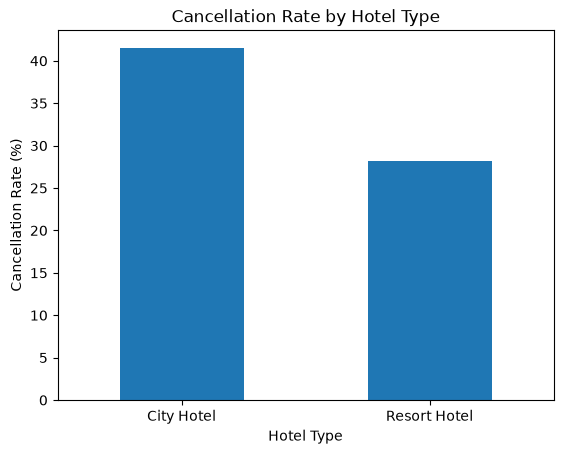

In [12]:
import matplotlib.pyplot as plt

cancellation_by_hotel = (
    df_train.groupby('hotel')['is_canceled'].mean() * 100
)

cancellation_by_hotel.plot(kind='bar')

plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [13]:
df_train.groupby('is_canceled')['lead_time'].mean()

is_canceled
0     79.875809
1    144.613289
Name: lead_time, dtype: float64

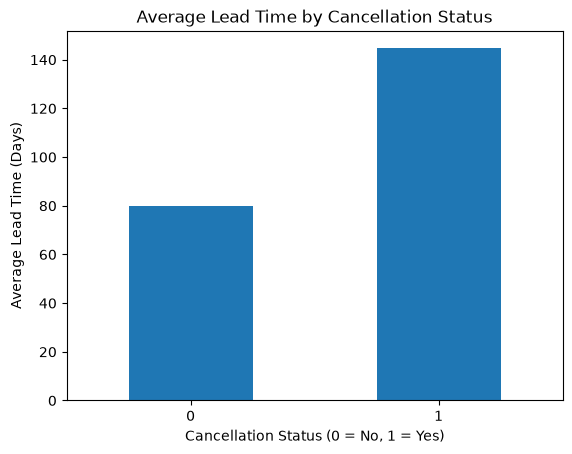

In [14]:
lead_time_by_cancellation = (
    df_train.groupby('is_canceled')['lead_time'].mean()
)

lead_time_by_cancellation.plot(kind='bar')

plt.title('Average Lead Time by Cancellation Status')
plt.xlabel('Cancellation Status (0 = No, 1 = Yes)')
plt.ylabel('Average Lead Time (Days)')
plt.xticks(rotation=0)
plt.show()

In [15]:
import pandas as pd

df_train = df_train.copy()

df_train['lead_time_group'] = pd.cut(
    df_train['lead_time'],
    bins=[-1, 30, 90, 180, float('inf')],
    labels=['0-30 days', '31-90 days', '91-180 days', '180+ days']
)

cancellation_by_lead_time = (
    df_train.groupby('lead_time_group', observed=True)['is_canceled']
    .mean() * 100
)

print(cancellation_by_lead_time)

lead_time_group
0-30 days      18.671199
31-90 days     37.729041
91-180 days    44.668046
180+ days      56.966071
Name: is_canceled, dtype: float64


In [16]:
df_train.groupby('deposit_type')['is_canceled'].agg(
    ['count', 'mean']
)

,count,mean
deposit_type,,
No Deposit,62769,0.283564
Non Refund,8770,0.993387
Refundable,95,0.242105


In [17]:
df_train.groupby('total_of_special_requests')['is_canceled'].agg(
    ['count', 'mean']
)

,count,mean
total_of_special_requests,,
0,42209,0.478050
1,19899,0.220564
2,7837,0.217303
3,1461,0.167009
4,200,0.100000
5,28,0.000000


In [18]:
numerical = df_train.select_dtypes(include=['int64', 'float64'])

correlations = (
    numerical.corr()['is_canceled']
    .drop('is_canceled')
    .sort_values(ascending=False)
)

print(correlations)

lead_time                         0.292808
previous_cancellations            0.112735
adults                            0.057645
adr                               0.042687
stays_in_week_nights              0.024597
arrival_date_year                 0.014905
arrival_date_week_number          0.008491
children                          0.006346
stays_in_weekend_nights           0.000272
arrival_date_day_of_month        -0.009122
babies                           -0.027333
previous_bookings_not_canceled   -0.056419
agent                            -0.078546
is_repeated_guest                -0.086469
required_car_parking_spaces      -0.195000
total_of_special_requests        -0.238714
Name: is_canceled, dtype: float64


In [19]:
from sklearn.metrics import mutual_info_score

categorical = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns

mi_scores = {}

for col in categorical:
    mi_scores[col] = mutual_info_score(
        X_train[col],
        y_train
    )

mi_scores = pd.Series(mi_scores).sort_values(ascending=False)

print(mi_scores)

deposit_type            0.131075
agent                   0.081824
country                 0.067755
market_segment          0.036789
distribution_channel    0.016405
customer_type           0.009396
hotel                   0.008716
reserved_room_type      0.002885
arrival_date_month      0.002514
meal                    0.001317
dtype: float64


In [20]:
from sklearn.feature_extraction import DictVectorizer

train_dicts = X_train.to_dict(orient='records')
val_dicts = X_val.to_dict(orient='records')

dv = DictVectorizer(sparse=True)

X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)

print("Train:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)

Train: (71634, 536)
Validation: (23878, 536)


In [23]:
import numpy as np

X_train_encoded.indices = X_train_encoded.indices.astype(np.int32)
X_train_encoded.indptr = X_train_encoded.indptr.astype(np.int32)

X_val_encoded.indices = X_val_encoded.indices.astype(np.int32)
X_val_encoded.indptr = X_val_encoded.indptr.astype(np.int32)

print(X_train_encoded.indices.dtype)
print(X_val_encoded.indices.dtype)

int32
int32


In [24]:
model.fit(X_train_encoded, y_train)

y_pred = model.predict_proba(X_val_encoded)[:, 1]

auc = roc_auc_score(y_val, y_pred)

print("Validation ROC AUC:", round(auc, 4))

Validation ROC AUC: 0.9011


In [25]:
train_no_deposit = X_train.drop(columns=['deposit_type'])
val_no_deposit = X_val.drop(columns=['deposit_type'])

dv_no_deposit = DictVectorizer(sparse=False)

X_train_no_deposit = dv_no_deposit.fit_transform(
    train_no_deposit.to_dict(orient='records')
)

X_val_no_deposit = dv_no_deposit.transform(
    val_no_deposit.to_dict(orient='records')
)

model_no_deposit = LogisticRegression(
    solver='liblinear',
    max_iter=1000,
    random_state=42
)

model_no_deposit.fit(X_train_no_deposit, y_train)

y_pred_no_deposit = model_no_deposit.predict_proba(
    X_val_no_deposit
)[:, 1]

auc_no_deposit = roc_auc_score(y_val, y_pred_no_deposit)

print("With deposit_type:", round(auc, 4))
print("Without deposit_type:", round(auc_no_deposit, 4))

With deposit_type: 0.9011
Without deposit_type: 0.8928


In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

rf_pred = rf_model.predict_proba(X_val_encoded)[:, 1]

rf_auc = roc_auc_score(y_val, rf_pred)

print("Logistic Regression AUC:", round(auc, 4))
print("Random Forest AUC:", round(rf_auc, 4))

Logistic Regression AUC: 0.9011
Random Forest AUC: 0.9254


In [27]:
import pandas as pd

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=dv.get_feature_names_out()
).sort_values(ascending=False)

print(feature_importance.head(15))

deposit_type=Non Refund          0.147966
deposit_type=No Deposit          0.126712
country=PRT                      0.105612
lead_time                        0.076446
total_of_special_requests        0.073709
previous_cancellations           0.050195
market_segment=Groups            0.036158
required_car_parking_spaces      0.032652
customer_type=Transient          0.026538
adr                              0.019974
market_segment=Online TA         0.018726
distribution_channel=TA/TO       0.017645
agent=9                          0.017103
customer_type=Transient-Party    0.016651
distribution_channel=Direct      0.013361
dtype: float64


In [29]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 65.9 MB/s  0:00:00s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 48.7 MB/s  0:00:05 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [30]:
import xgboost as xgb

dtrain = xgb.DMatrix(
    X_train_encoded,
    label=y_train
)

dval = xgb.DMatrix(
    X_val_encoded,
    label=y_val
)

xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 42,
    'nthread': 4
}

xgb_model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=[(dval, 'validation')],
    verbose_eval=False
)

xgb_pred = xgb_model.predict(dval)

xgb_auc = roc_auc_score(y_val, xgb_pred)

print("Logistic Regression:", round(auc, 4))
print("Random Forest:", round(rf_auc, 4))
print("XGBoost:", round(xgb_auc, 4))

Logistic Regression: 0.9011
Random Forest: 0.9254
XGBoost: 0.9449


In [31]:
depth_scores = {}

for depth in [3, 6, 9]:
    params = xgb_params.copy()
    params['max_depth'] = depth

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=200,
        verbose_eval=False
    )

    y_pred = model.predict(dval)
    score = roc_auc_score(y_val, y_pred)

    depth_scores[depth] = score

    print(f"max_depth={depth}: AUC={score:.4f}")

max_depth=3: AUC=0.9332
max_depth=6: AUC=0.9449
max_depth=9: AUC=0.9506


In [32]:
eta_scores = {}

for eta in [0.3, 0.1, 0.05]:
    params = xgb_params.copy()
    params['max_depth'] = 9
    params['eta'] = eta

    model = xgb.train(
        params,
        dtrain,
        num_boost_round=200,
        verbose_eval=False
    )

    y_pred = model.predict(dval)
    score = roc_auc_score(y_val, y_pred)

    eta_scores[eta] = score

    print(f"eta={eta}: AUC={score:.4f}")

eta=0.3: AUC=0.9547
eta=0.1: AUC=0.9506
eta=0.05: AUC=0.9477


In [33]:
best_params = xgb_params.copy()

best_params['max_depth'] = 9
best_params['eta'] = 0.3

model_tuned = xgb.train(
    best_params,
    dtrain,
    num_boost_round=500,
    evals=[(dtrain, 'train'), (dval, 'validation')],
    early_stopping_rounds=30,
    verbose_eval=False
)

print("Best iteration:", model_tuned.best_iteration)
print("Best Validation AUC:", model_tuned.best_score)

Best iteration: 261
Best Validation AUC: 0.9551249320460504


In [34]:
from sklearn.feature_extraction import DictVectorizer

train_safe = X_train.drop(
    columns=['total_of_special_requests']
)

val_safe = X_val.drop(
    columns=['total_of_special_requests']
)

dv_safe = DictVectorizer(sparse=False)

X_train_safe = dv_safe.fit_transform(
    train_safe.to_dict(orient='records')
)

X_val_safe = dv_safe.transform(
    val_safe.to_dict(orient='records')
)

dtrain_safe = xgb.DMatrix(
    X_train_safe,
    label=y_train
)

dval_safe = xgb.DMatrix(
    X_val_safe,
    label=y_val
)

model_safe = xgb.train(
    best_params,
    dtrain_safe,
    num_boost_round=262,
    verbose_eval=False
)

safe_pred = model_safe.predict(dval_safe)

safe_auc = roc_auc_score(y_val, safe_pred)

print("Original XGBoost AUC:", round(model_tuned.best_score, 4))
print("Without special requests:", round(safe_auc, 4))

Original XGBoost AUC: 0.9551
Without special requests: 0.9435


In [35]:
booking_features = [
    'hotel',
    'lead_time',
    'arrival_date_year',
    'arrival_date_month',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'meal',
    'country',
    'market_segment',
    'distribution_channel',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'reserved_room_type',
    'deposit_type',
    'agent',
    'customer_type',
    'adr'
]

print("Number of features:", len(booking_features))

Number of features: 23


In [36]:
# Select booking-time features
X_train_final = X_train[booking_features]
X_val_final = X_val[booking_features]

# Encode categorical features
dv_final = DictVectorizer(sparse=False)

X_train_final_encoded = dv_final.fit_transform(
    X_train_final.to_dict(orient='records')
)

X_val_final_encoded = dv_final.transform(
    X_val_final.to_dict(orient='records')
)

# Create XGBoost datasets
dtrain_final = xgb.DMatrix(
    X_train_final_encoded,
    label=y_train
)

dval_final = xgb.DMatrix(
    X_val_final_encoded,
    label=y_val
)

# Train model with early stopping
model_final_candidate = xgb.train(
    best_params,
    dtrain_final,
    num_boost_round=500,
    evals=[(dtrain_final, 'train'), (dval_final, 'validation')],
    early_stopping_rounds=30,
    verbose_eval=False
)

print("Best iteration:", model_final_candidate.best_iteration)
print("Validation ROC AUC:", model_final_candidate.best_score)

Best iteration: 228
Validation ROC AUC: 0.9347988523608717


In [37]:
train_pred = model_final_candidate.predict(
    dtrain_final,
    iteration_range=(0, model_final_candidate.best_iteration + 1)
)

val_pred = model_final_candidate.predict(
    dval_final,
    iteration_range=(0, model_final_candidate.best_iteration + 1)
)

train_auc = roc_auc_score(y_train, train_pred)
val_auc = roc_auc_score(y_val, val_pred)

print("Train ROC AUC:", round(train_auc, 4))
print("Validation ROC AUC:", round(val_auc, 4))
print("Difference:", round(train_auc - val_auc, 4))

Train ROC AUC: 0.9878
Validation ROC AUC: 0.9348
Difference: 0.053


In [38]:
for depth in [3, 5, 7]:
    params = best_params.copy()
    params['max_depth'] = depth

    model = xgb.train(
        params,
        dtrain_final,
        num_boost_round=500,
        evals=[(dval_final, 'validation')],
        early_stopping_rounds=30,
        verbose_eval=False
    )

    best_round = model.best_iteration + 1

    train_pred = model.predict(
        dtrain_final,
        iteration_range=(0, best_round)
    )

    val_pred = model.predict(
        dval_final,
        iteration_range=(0, best_round)
    )

    train_score = roc_auc_score(y_train, train_pred)
    val_score = roc_auc_score(y_val, val_pred)

    print(
        f"Depth={depth} | "
        f"Train={train_score:.4f} | "
        f"Val={val_score:.4f} | "
        f"Gap={train_score - val_score:.4f} | "
        f"Rounds={best_round}"
    )

Depth=3 | Train=0.9362 | Val=0.9253 | Gap=0.0110 | Rounds=499
Depth=5 | Train=0.9649 | Val=0.9315 | Gap=0.0335 | Rounds=500
Depth=7 | Train=0.9817 | Val=0.9340 | Gap=0.0477 | Rounds=363


In [39]:
for weight in [1, 5, 10]:
    params = best_params.copy()
    params['max_depth'] = 7
    params['min_child_weight'] = weight

    model = xgb.train(
        params,
        dtrain_final,
        num_boost_round=500,
        evals=[(dval_final, 'validation')],
        early_stopping_rounds=30,
        verbose_eval=False
    )

    best_round = model.best_iteration + 1

    train_pred = model.predict(
        dtrain_final,
        iteration_range=(0, best_round)
    )

    val_pred = model.predict(
        dval_final,
        iteration_range=(0, best_round)
    )

    train_score = roc_auc_score(y_train, train_pred)
    val_score = roc_auc_score(y_val, val_pred)

    print(
        f"min_child_weight={weight} | "
        f"Train={train_score:.4f} | "
        f"Val={val_score:.4f} | "
        f"Gap={train_score - val_score:.4f} | "
        f"Rounds={best_round}"
    )

min_child_weight=1 | Train=0.9817 | Val=0.9340 | Gap=0.0477 | Rounds=363
min_child_weight=5 | Train=0.9722 | Val=0.9332 | Gap=0.0390 | Rounds=265
min_child_weight=10 | Train=0.9562 | Val=0.9312 | Gap=0.0250 | Rounds=145


In [40]:
final_params = best_params.copy()

final_params['max_depth'] = 7
final_params['min_child_weight'] = 5

selected_model = xgb.train(
    final_params,
    dtrain_final,
    num_boost_round=500,
    evals=[(dval_final, 'validation')],
    early_stopping_rounds=30,
    verbose_eval=False
)

selected_rounds = selected_model.best_iteration + 1

print("Selected rounds:", selected_rounds)
print("Validation ROC AUC:", selected_model.best_score)
print("Number of features:", X_train_final_encoded.shape[1])

Selected rounds: 265
Validation ROC AUC: 0.9331528447853764
Number of features: 534


In [41]:
import pandas as pd

X_full_train = pd.concat(
    [X_train, X_val],
    axis=0
)

y_full_train = pd.concat(
    [
        pd.Series(y_train),
        pd.Series(y_val)
    ],
    ignore_index=True
)

print("Full Train:", X_full_train.shape)
print("Target:", y_full_train.shape)

Full Train: (95512, 25)
Target: (95512,)


In [42]:
# Select the 23 features
X_full_train_selected = X_full_train[booking_features].copy()

# Convert rows to dictionaries
full_train_dicts = X_full_train_selected.to_dict(
    orient='records'
)

# Encode features
dv_full = DictVectorizer(sparse=False)

X_full_train_encoded = dv_full.fit_transform(
    full_train_dicts
)

print("Full Train:", X_full_train_encoded.shape)
print("Target:", y_full_train.shape)

Full Train: (95512, 563)
Target: (95512,)


In [43]:
# Create DMatrix
dfulltrain = xgb.DMatrix(
    X_full_train_encoded,
    label=y_full_train
)

# Train the final model
final_model = xgb.train(
    final_params,
    dfulltrain,
    num_boost_round=265,
    verbose_eval=False
)

print("Final model trained successfully!")
print("Number of boosting rounds:", final_model.num_boosted_rounds())

Final model trained successfully!
Number of boosting rounds: 265


In [44]:
# Select the same 23 features
X_test_selected = X_test[booking_features].copy()

# Convert test data to dictionaries
test_dicts = X_test_selected.to_dict(orient='records')

# Encode using the existing DictVectorizer
X_test_encoded = dv_full.transform(test_dicts)

# Create DMatrix
dtest = xgb.DMatrix(X_test_encoded)

# Predict cancellation probabilities
y_pred = final_model.predict(dtest)

# Calculate ROC AUC
test_auc = roc_auc_score(y_test, y_pred)

print("Test ROC AUC:", round(test_auc, 4))

Test ROC AUC: 0.935


In [45]:
import pickle

# Save XGBoost model
final_model.save_model('model.json')

# Save DictVectorizer
with open('dv.bin', 'wb') as f:
    pickle.dump(dv_full, f)

print("Model and DictVectorizer saved successfully!")

Model and DictVectorizer saved successfully!
